# 05 - Circle construction (grouping pipes into work units)

**Author of this notebook:** Qusai (qusai branch). Plan step 5, part 1 of 2
(part 2 = ordering, notebook 06). Needs `src/pipeplan` (notebook 04 explains the simulator).

## The problem
Every iron pipe must lie **wholly inside at least one circle**. We choose the circles'
centres and radii. The circles' *order* is decided later; here we decide **which pipes
share a circle**.

Cost of a circle = `100 + (surface_rate x area)^0.85 + 200 x metres of non-poly pipe inside`.
* The `200 x metres` part is paid exactly once per pipe, however we group them - it is
  not affected by grouping (about $88M for the iron, $94M including copper/brass).
* So grouping only changes the **fixed cost** `100 + (s x A)^0.85`. That is the quantity
  to minimise (together with a time penalty - see below).

## Method: bottom-up merging with the real cost as the criterion
1. Start with one tiny circle per target pipe (the smallest circle through its 2 end points).
2. For each circle look at its 8 nearest neighbouring circles. For each candidate pair compute the
   **smallest circle enclosing both**, and the exact fixed cost of that circle (including
   every pipe that falls inside, whatever its material, since all of them count towards
   the surface rate). A circle swallowing another circle's pipes entirely **absorbs** it.
3. `gain = (fixed cost before) - (fixed cost after)`  minus a **delay penalty** (explained below).
4. Apply the best non-conflicting merges, then repeat until no merge has positive gain.

### The delay penalty
A merged circle is dug as one lump. If it ties a high-risk pipe to low-risk ones, the
risky pipe waits longer, and each waiting year costs expected leak dollars. We estimate
that cost with a provisional schedule (circles sorted by expected loss per dollar; see
notebook 06) and a linear-time approximation. Without the penalty the final score is
about $0.7M lower (see the sensitivity table at the end).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.collections import LineCollection

from pipeplan.world import load_world, SURFACES
from pipeplan.construct import Builder, Params, choose_targets
from pipeplan.simulator import prepare, fixed_cost
from pipeplan.pipeline import independent_coverage_check

pd.set_option("display.width", 160)
w = load_world()

## 1. Why merging helps only sometimes
Two neighbouring 17 m pipes, 10 m apart. Fixed cost of two separate tiny circles vs one
circle around both, for different surfaces:

In [2]:
rows = []
for name in ["grassland", "farmland", "water", "structure"]:
    s = {"grassland": 3, "farmland": 7, "water": 32, "structure": 50}[name]
    L, gap = 17.0, 10.0
    separate = 2 * fixed_cost(s, L / 2)
    # smallest circle enclosing two parallel 17 m pipes `gap` apart: r = sqrt((L/2)^2 + (gap/2)^2)
    merged = fixed_cost(s, np.hypot(L / 2, gap / 2))
    rows.append({"surface": name, "two separate circles $": separate, "one merged circle $": merged,
                 "merge saves $": separate - merged})
pd.DataFrame(rows).round(0)

,surface,two separate circles $,one merged circle $,merge saves $
0,grassland,712.0,429.0,282.0
1,farmland,1252.0,777.0,475.0
2,water,4028.0,2564.0,1464.0
3,structure,5794.0,3701.0,2093.0


Merging pays when the pipes are close together **and** the area is cheap. Because the
exponent is 0.85 (not much below 1), cost grows like radius^1.7, so a circle twice as wide
costs ~3.2x as much: stretching a circle along a pipeline never pays; bundling pipes that
sit side-by-side in a compact blob does. Surfaces matter most: `water` ($32/m^2) and
`structure` ($50/m^2) circles are expensive, so we expect few big circles there.

## 2. Which pipes are targets?
* **Mandatory:** all 26,245 iron pipes (incl. the 8 blank-material pipes, treated as iron).
* **Optional:** 1,003 copper/brass pipes. They are not required, but they keep leaking
  (brass is the leakiest material per km in Daniel's EDA) and every leak is billed to us.
  An optional pipe becomes a target if replacing it *on its own* pays for itself within
  `h_opt = 12` years: `K x (1 - (1-p)^12) > 200 x length + its own circle's fixed cost`.
  (Optional pipes that a circle swallows by accident are also priced in.)

In [3]:
params = Params(verbose=True)
target, optional = choose_targets(w, params)
tab = pd.DataFrame({"material": w.material[optional], "targeted": target[optional]})
print(tab.groupby("material").targeted.agg(["size", "sum"]).rename(columns={"size": "optional pipes", "sum": "targeted"}))
print("\ntotal targets:", int(target.sum()), "(26,245 iron +", int((target & optional).sum()), "optional)")

          optional pipes  targeted
material                          
brass                307       289
copper               696        86

total targets: 26620 (26,245 iron + 375 optional)


## 3. Run the merging
(Takes about a minute. Each line is one round: circles before -> after, number of merges,
total fixed cost of all current circles.)

In [4]:
builder = Builder(w, params).run()

round   1:  26620 ->  15189 circles (3739 merges), total fixed cost $53,057,825


round   2:  15189 ->  13422 circles (875 merges), total fixed cost $51,611,192


round   3:  13422 ->  13088 circles (189 merges), total fixed cost $51,367,869


round   4:  13088 ->  13031 circles (34 merges), total fixed cost $51,330,964


round   5:  13031 ->  13018 circles (3 merges), total fixed cost $51,320,555


...

round   7:  13009 ->  12996 circles (1 merges), total fixed cost $51,308,494


round   8:  12996 ->  12993 circles (1 merges), total fixed cost $51,305,877


round   9:  12993 ->  12983 circles (1 merges), total fixed cost $51,298,590


round  10:  12983 ->  12981 circles (1 merges), total fixed cost $51,298,020


round  11:  12981 ->  12981 circles (0 merges), total fixed cost $51,298,020


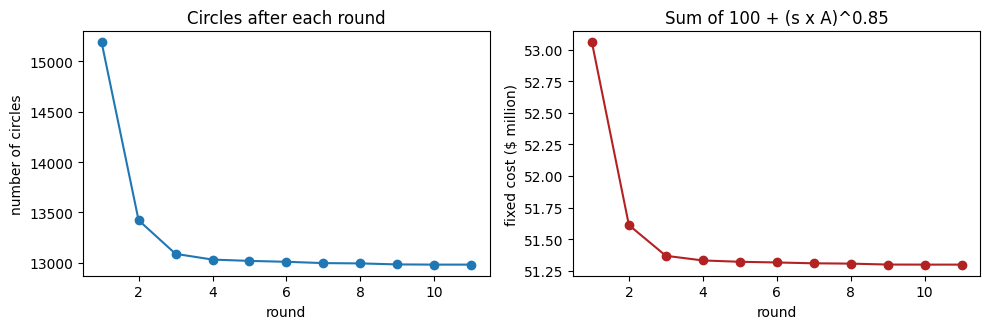

In [5]:
hist = pd.DataFrame(builder.history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist["round"], hist["clusters"], "o-")
ax[0].set_xlabel("round"); ax[0].set_ylabel("number of circles"); ax[0].set_title("Circles after each round")
ax[1].plot(hist["round"], hist["fixed_cost"] / 1e6, "o-", color="firebrick")
ax[1].set_xlabel("round"); ax[1].set_ylabel("fixed cost ($ million)"); ax[1].set_title("Sum of 100 + (s x A)^0.85")
plt.tight_layout(); plt.show()

## 4. What came out

In [6]:
circles = builder.circles()  # centres rounded to the cent, radius rounded UP to the cent
prep = prepare(w, circles)
cov = independent_coverage_check(w, circles)
singles_F = sum(fixed_cost(w.surface_rate(np.array([i])), w.length[i] / 2 + 0.10) for i in np.flatnonzero(target))
summary = pd.Series({
    "target pipes": int(target.sum()),
    "circles": len(circles),
    "average target pipes per circle": round(target.sum() / len(circles), 2),
    "fixed cost, one circle per pipe $": round(singles_F),
    "fixed cost after merging $": round(prep.fixed.sum()),
    "saving $": round(singles_F - prep.fixed.sum()),
    "iron pipes NOT covered (independent check)": cov["n_uncovered"],
    "tightest margin of any iron pipe inside its circle (m)": round(cov["min_margin_m"], 3),
})
summary

target pipes                                                 26620.00
circles                                                      12981.00
average target pipes per circle                                  2.05
fixed cost, one circle per pipe $                         59757487.00
fixed cost after merging $                                51118674.00
saving $                                                   8638812.00
iron pipes NOT covered (independent check)                       0.00
tightest margin of any iron pipe inside its circle (m)           0.05
dtype: float64

`iron pipes NOT covered` must be 0 or the website rejects the submission. The check is a
brute-force numpy test (every iron pipe against every circle, no KD-tree), so a bug in
the faster geometry code cannot hide. The *margin* is how far inside its circle the
worst pipe sits (we round radii up and add a 0.05 m cushion so floating-point or
tolerance differences in the website's checker cannot push a pipe outside).

In [7]:
nt = np.array([int(w.nonpoly0[prep.members(j)].sum()) for j in range(prep.n)])
df = pd.DataFrame({"radius": circles[:, 2], "surface_rate": prep.surface_rate, "fixed_cost": prep.fixed, "pipes": nt})
by = df.groupby("surface_rate").agg(circles=("pipes", "size"), pipes=("pipes", "sum"),
                                    mean_radius=("radius", "mean"), fixed_cost=("fixed_cost", "sum"))
by["cost_per_circle"] = by.fixed_cost / by.circles
by.sort_values("fixed_cost", ascending=False).head(10).round(0)

,circles,pipes,mean_radius,fixed_cost,cost_per_circle
surface_rate,,,,,
32.0,4202,6330,12.0,19740368.0,4698.0
50.0,1500,2882,16.0,15617167.0,10411.0
17.0,721,876,13.0,2290101.0,3176.0
82.0,68,286,24.0,2058315.0,30269.0
3.0,3414,8327,10.0,2014322.0,590.0
53.0,75,527,25.0,1644633.0,21928.0
7.0,2108,4025,8.0,1411443.0,670.0
12.0,404,1267,13.0,1161132.0,2874.0
20.0,159,920,20.0,1048699.0,6596.0


`surface_rate` is the summed rate of the surfaces in the circle (32 = water only,
50 = structure only, 3 = grassland only, 82 = water + structure, ...). Single-surface
`water` and `structure` circles dominate the fixed cost: that is where merging pays least,
because those surfaces are $32 and $50 per m^2.

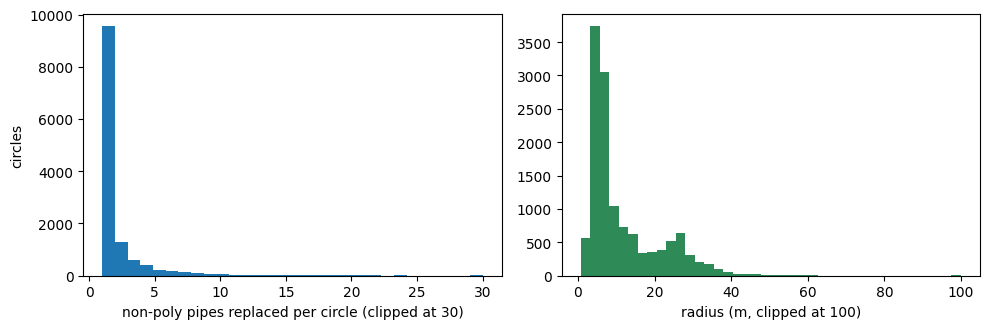

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(df.pipes.clip(upper=30), bins=30)
ax[0].set_xlabel("non-poly pipes replaced per circle (clipped at 30)"); ax[0].set_ylabel("circles")
ax[1].hist(df.radius.clip(upper=100), bins=40, color="seagreen")
ax[1].set_xlabel("radius (m, clipped at 100)")
plt.tight_layout(); plt.show()

## 5. A picture: one neighbourhood
The window below is centred on the circle that replaces the most pipes. Pipes are
coloured by whether they still need replacing (red = non-poly, grey = already polyurethane);
blue rings are the work units.

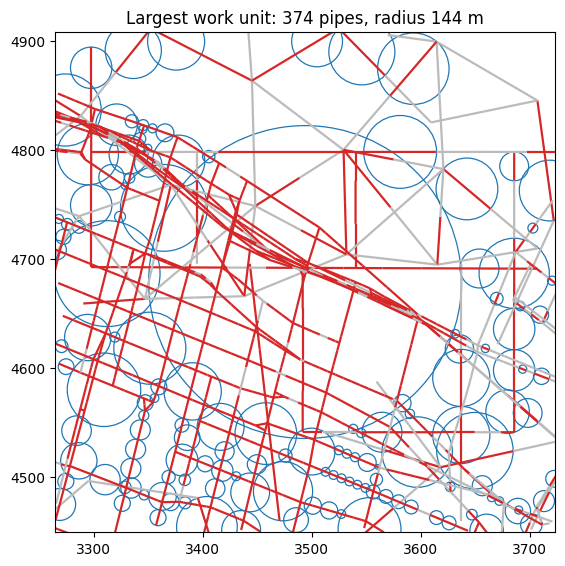

In [9]:
big = int(np.argmax(nt))
cx, cy = circles[big, 0], circles[big, 1]
half = max(60.0, circles[big, 2] * 1.6)
sel = (np.abs(w.mx - cx) < half) & (np.abs(w.my - cy) < half)
segs = np.stack([np.column_stack([w.x1[sel], w.y1[sel]]), np.column_stack([w.x2[sel], w.y2[sel]])], axis=1)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_collection(LineCollection(segs, colors=np.where(w.nonpoly0[sel], "#d62728", "#bbbbbb"), linewidths=1.6))
for x, y, r in circles:
    if abs(x - cx) < half and abs(y - cy) < half:
        ax.add_patch(Circle((x, y), r, fill=False, ec="#1f77b4", lw=0.9))
ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half); ax.set_aspect("equal")
ax.set_title(f"Largest work unit: {nt[big]} pipes, radius {circles[big,2]:.0f} m")
plt.show()

## 6. Save the (still unordered) circles for notebook 06
`circles_unordered_v1.csv` is the list of circles *before* ordering. Order matters a lot
for the score and is decided in the next notebook.

In [10]:
out = ROOT / "data" / "processed" / "circles_unordered_v1.csv"
pd.DataFrame(circles, columns=["x", "y", "r"]).to_csv(out, index=False)
print("saved", out.relative_to(ROOT), len(circles), "circles")

saved data\processed\circles_unordered_v1.csv 12981 circles


## 7. How sensitive is this to the settings?
`scripts/sensitivity.py` rebuilds + orders the plan under different settings (about 5 min)
and writes `data/processed/sensitivity_construction.csv`. Scores are the fast,
model-based `expected_score` (conservative; see notebook 04).

In [11]:
sens_path = ROOT / "data" / "processed" / "sensitivity_construction.csv"
if sens_path.exists():
    sens = pd.read_csv(sens_path)
    sens["expected_score_M"] = (sens.expected_score / 1e6).round(2)
    sens["fixed_cost_M"] = (sens.fixed_cost / 1e6).round(2)
    display_cols = ["variant", "circles", "optional_pipes_targeted", "fixed_cost_M", "expected_score_M", "last_year", "covers_all_iron"]
    print(sens[display_cols].to_string(index=False))
else:
    print("run scripts/sensitivity.py first")

                           variant  circles  optional_pipes_targeted  fixed_cost_M  expected_score_M  last_year  covers_all_iron
                           default    12981                      375         51.30             73.21       2041             True
             no time-aware penalty    12240                      375         50.90             72.51       2041             True
                 16 merge partners    12268                      375         51.20             72.60       2041             True
                  max radius 300 m    12981                      375         51.30             73.21       2041             True
                 max radius 1000 m    12981                      375         51.30             73.21       2041             True
no optional copper/brass (h_opt~0)    12733                        0         50.52             65.45       2040             True
              optional horizon 6 y    12955                      329         51.10             73

### Reading the table
* Pairwise merging stops improving after ~10 rounds: changing the candidate partners or
  the optional-pipe horizon moves the score by about 1% or less. The radius cap (300 / 600 /
  1000 m) never binds - the largest circle is ~140 m - so those rows are identical. The
  remaining cost is dominated by `water` and `structure` single-pipe circles that
  cannot be merged cheaply.
* Including the profitable copper/brass pipes is worth ~$8M (compare "no optional
  copper/brass" to the default) - the biggest lever in this table.
* The time-aware penalty and the 0.02 m margin rows show the price of each choice: the
  penalty is worth ~$0.7M; the larger safety margin costs ~$0.3M.

## Known limitations / ideas for the group
* Merging is **pairwise and greedy**; a group of 10 pipes that only pays off as a whole
  (but not any 2 of them) is missed. A set-cover / local-search step could improve this.
* Circles are centred on their pipes' minimum enclosing circle; shifting a centre to
  dodge one expensive surface pipe at the edge is not tried.
* Costs use the mean leak cost and constant hazards from Cheryl's model.